[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/lectures/10_diffusion.ipynb)

# Lecture 10 — Denoising Diffusion Models

**Neural Networks · Master's course**

In Lecture 9 we met two ideas that seemed unrelated: the **variational
autoencoder**, a latent-variable model trained with an evidence lower bound, and the
**denoising autoencoder**, whose denoising direction approximates the score
$\nabla_{\mathbf x}\log p(\mathbf x)$. Diffusion models combine both, and they are the
model family behind today's image, video and audio generators.

The idea fits in one sentence: *destroy data slowly by adding noise, and learn to
undo the destruction one small step at a time.* In this lecture we

1. define the **forward (noising) process** and derive its closed form $q(\mathbf x_t\mid\mathbf x_0)$,
2. study **noise schedules** (linear vs cosine) through $\bar\alpha_t$ and the signal-to-noise ratio,
3. derive the **reverse process** and the DDPM training objective (predict the noise $\boldsymbol\epsilon$),
   and connect it to the ELBO and to **denoising score matching**,
4. implement training and **ancestral sampling** on 2-D toy data and watch the reverse process,
5. train a small DDPM on the $8\times8$ digits,
6. look at **faster sampling (DDIM)** and **classifier-free guidance**, and
7. close by connecting this lecture to the rest of the course.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits, make_moons
from sklearn.neighbors import NearestNeighbors

torch.manual_seed(0)
rng = np.random.default_rng(0)
torch.set_num_threads(2)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True

## 1. Intuition

Take a data point $\mathbf x_0$ (an image, or a point in the plane) and add a
little Gaussian noise, then a little more, for $T$ steps. After enough steps
the result $\mathbf x_T$ is indistinguishable from pure noise
$\mathcal N(\mathbf 0, I)$, whatever $\mathbf x_0$ was. This **forward process**
has no parameters; it is fixed in advance.

Now suppose we could run the film backwards: start from noise $\mathbf x_T\sim\mathcal N(\mathbf 0,I)$
and repeatedly remove a little noise until we reach a sample $\mathbf x_0$ from the
data distribution. Each individual backward step only has to undo a *small*
corruption, and when the noise added per step is small, the backward step is itself
approximately Gaussian. So we learn a network that, given a noisy $\mathbf x_t$ and the
time $t$, predicts how to denoise it. Generating data becomes a sequence of $T$ easy
denoising problems instead of one hard one.

Compare with the VAE: there the encoder $q_\phi(\mathbf z\mid\mathbf x)$ was learned and
the decoder had to map noise to data in a single pass. Here the "encoder" is fixed
(adding noise) and the "decoder" is applied $T$ times.

We use a 2-D dataset throughout the derivation so that we can *see* every distribution.

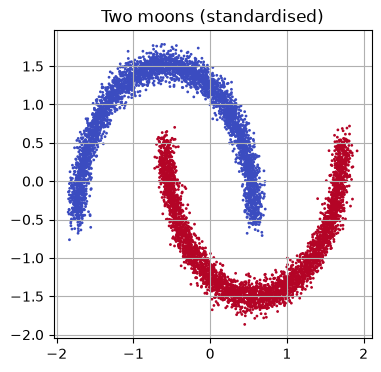

In [2]:
X_moons, y_moons = make_moons(n_samples=8000, noise=0.05, random_state=0)
m_mean, m_std = X_moons.mean(0), X_moons.std(0)
X2 = ((X_moons - m_mean) / m_std).astype(np.float32)     # standardised: mean 0, std 1 per coordinate
X2_t = torch.from_numpy(X2)
y2_t = torch.from_numpy(y_moons).long()
plt.scatter(X2[:, 0], X2[:, 1], s=1, c=y_moons, cmap="coolwarm")
plt.gca().set_aspect("equal"); plt.title("Two moons (standardised)"); plt.show()

## 2. The forward process

Choose a **variance schedule** $0 < \beta_1 < \dots < \beta_T < 1$ and define the Markov chain

$$q(\mathbf x_t\mid\mathbf x_{t-1}) = \mathcal N\big(\mathbf x_t;\ \sqrt{1-\beta_t}\,\mathbf x_{t-1},\ \beta_t I\big), \qquad t = 1,\dots,T.$$

In words: shrink the previous point slightly towards the origin and add noise of
variance $\beta_t$. The shrinking factor $\sqrt{1-\beta_t}$ is chosen so that the
variance stays bounded: if $\operatorname{Var}[\mathbf x_{t-1}] = I$ then
$\operatorname{Var}[\mathbf x_t] = (1-\beta_t)I + \beta_t I = I$ ("variance preserving").

### 2.1 Jumping straight to step $t$

Write $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s=1}^t\alpha_s$. With the
reparameterisation from Lecture 9, one step reads
$\mathbf x_t = \sqrt{\alpha_t}\,\mathbf x_{t-1} + \sqrt{1-\alpha_t}\,\boldsymbol\epsilon_{t}$
with independent $\boldsymbol\epsilon_t\sim\mathcal N(\mathbf 0,I)$. Unroll two steps:

$$\mathbf x_t = \sqrt{\alpha_t}\Big(\sqrt{\alpha_{t-1}}\,\mathbf x_{t-2} + \sqrt{1-\alpha_{t-1}}\,\boldsymbol\epsilon_{t-1}\Big) + \sqrt{1-\alpha_t}\,\boldsymbol\epsilon_t
= \sqrt{\alpha_t\alpha_{t-1}}\,\mathbf x_{t-2} + \underbrace{\sqrt{\alpha_t(1-\alpha_{t-1})}\,\boldsymbol\epsilon_{t-1} + \sqrt{1-\alpha_t}\,\boldsymbol\epsilon_t}_{\text{sum of independent Gaussians}} .$$

A sum of independent zero-mean Gaussians is Gaussian with the variances added:
$\alpha_t(1-\alpha_{t-1}) + (1-\alpha_t) = 1-\alpha_t\alpha_{t-1}$. So
$\mathbf x_t = \sqrt{\alpha_t\alpha_{t-1}}\,\mathbf x_{t-2} + \sqrt{1-\alpha_t\alpha_{t-1}}\,\bar{\boldsymbol\epsilon}$,
which has exactly the same form with $\alpha_t$ replaced by $\alpha_t\alpha_{t-1}$.
By induction down to $\mathbf x_0$:

$$\boxed{\;q(\mathbf x_t\mid\mathbf x_0) = \mathcal N\big(\mathbf x_t;\ \sqrt{\bar\alpha_t}\,\mathbf x_0,\ (1-\bar\alpha_t)\,I\big)
\quad\Longleftrightarrow\quad \mathbf x_t = \sqrt{\bar\alpha_t}\,\mathbf x_0 + \sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon,\ \ \boldsymbol\epsilon\sim\mathcal N(\mathbf 0, I).\;}$$

This closed form is what makes diffusion models practical: during training we never
simulate the chain; we sample a random $t$ and produce $\mathbf x_t$ in one line.
If $\bar\alpha_T\approx 0$ then $q(\mathbf x_T\mid\mathbf x_0)\approx\mathcal N(\mathbf 0, I)$ for every
$\mathbf x_0$: the information about the data is destroyed.

**Implementation convention.** We store schedule quantities in arrays of length
$T+1$ and index them directly by $t\in\{0,\dots,T\}$, with $\beta_0 = 0$ and
$\bar\alpha_0 = 1$ (so $\mathbf x_0$ is the clean data). When $t$ is a batch of
time steps of shape `(B,)`, `alpha_bar[t]` has shape `(B,)` and must be reshaped to
`(B, 1)` before multiplying a batch of data of shape `(B, d)`.

In [3]:
def make_schedule(betas):
    """betas: NumPy array of length T (for t = 1..T). Returns float32 tensors of length T+1."""
    betas = np.concatenate([[0.0], np.asarray(betas, dtype=np.float64)])
    alphas = 1.0 - betas
    alpha_bar = np.cumprod(alphas)
    alpha_bar_prev = np.concatenate([[1.0], alpha_bar[:-1]])
    # variance of the true posterior q(x_{t-1} | x_t, x_0), see Section 3 (0 at t = 0 and t = 1)
    post_var = np.zeros_like(betas)
    post_var[1:] = betas[1:] * (1.0 - alpha_bar_prev[1:]) / (1.0 - alpha_bar[1:])
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(T=len(betas) - 1, betas=as_t(betas), alphas=as_t(alphas), alpha_bar=as_t(alpha_bar),
                alpha_bar_prev=as_t(alpha_bar_prev), post_var=as_t(post_var))

def linear_betas(T, beta_1=1e-4, beta_T=0.02):
    return np.linspace(beta_1, beta_T, T)

def q_sample(x0, t, noise, sched):
    """Sample x_t ~ q(x_t | x_0) for a batch. x0, noise: (B, d); t: (B,) long tensor in 0..T."""
    ab = sched["alpha_bar"][t].reshape(-1, 1)            # (B, 1) broadcasts over the d coordinates
    return ab.sqrt() * x0 + (1.0 - ab).sqrt() * noise

# A quick empirical check of the closed form: noise a single point many times
sched_check = make_schedule(linear_betas(100, 1e-4, 0.1))
x0_rep = torch.tensor([[1.0, -2.0]]).repeat(50_000, 1)
t_rep = torch.full((50_000,), 30, dtype=torch.long)
xt_rep = q_sample(x0_rep, t_rep, torch.randn_like(x0_rep), sched_check)
ab30 = sched_check["alpha_bar"][30].item()
print(f"alpha_bar_30 = {ab30:.4f}")
print("empirical mean", xt_rep.mean(0).numpy().round(3), " expected", (math.sqrt(ab30) * x0_rep[0]).numpy().round(3))
print("empirical var ", xt_rep.var(0).numpy().round(3), " expected", round(1 - ab30, 3))

alpha_bar_30 = 0.6399
empirical mean [ 0.798 -1.601]  expected [ 0.8 -1.6]
empirical var  [0.36  0.362]  expected 0.36


Here is the forward process applied to the whole moons dataset. We use $T = 100$ steps and
a linear schedule from $\beta_1 = 10^{-4}$ to $\beta_T = 0.1$ for the 2-D experiments.

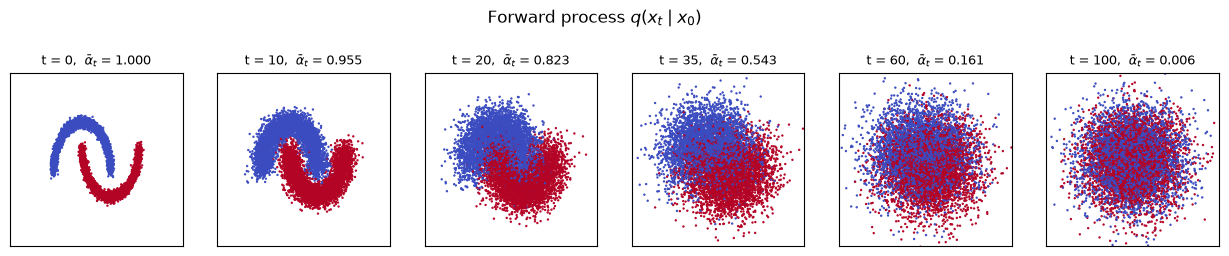

In [4]:
T2 = 100
sched2 = make_schedule(linear_betas(T2, 1e-4, 0.1))
snap_ts = [0, 10, 20, 35, 60, 100]
fig, axes = plt.subplots(1, len(snap_ts), figsize=(2.6 * len(snap_ts), 2.8))
noise_fixed = torch.randn_like(X2_t)
for ax, t in zip(axes, snap_ts):
    xt = q_sample(X2_t, torch.full((len(X2_t),), t, dtype=torch.long), noise_fixed, sched2).numpy()
    ax.scatter(xt[:, 0], xt[:, 1], s=0.5, c=y_moons, cmap="coolwarm")
    ax.set_title(f"t = {t},  $\\bar\\alpha_t$ = {sched2['alpha_bar'][t].item():.3f}", fontsize=9)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Forward process $q(x_t\\mid x_0)$", y=1.03); plt.show()

### 2.2 Noise schedules

The schedule determines how quickly information is destroyed. The natural quantity
to look at is the **signal-to-noise ratio**

$$\mathrm{SNR}(t) = \frac{\bar\alpha_t}{1-\bar\alpha_t},$$

the ratio of the variance of the signal term $\sqrt{\bar\alpha_t}\mathbf x_0$ (for unit-variance data)
to that of the noise term. It decreases monotonically from $\infty$ at $t=0$ towards $0$.

* The **linear schedule** of Ho et al. (2020) uses $\beta_t$ linearly spaced from
  $10^{-4}$ to $0.02$ with $T=1000$.
* The **cosine schedule** of Nichol & Dhariwal (2021) defines $\bar\alpha_t$ directly,

  $$\bar\alpha_t = \frac{f(t)}{f(0)},\qquad f(t) = \cos^2\!\Big(\frac{t/T + s}{1+s}\cdot\frac{\pi}{2}\Big),\quad s = 0.008,$$

  and recovers $\beta_t = 1 - \bar\alpha_t/\bar\alpha_{t-1}$, clipped at $0.999$ to avoid a
  singularity at $t=T$. The small offset $s$ prevents $\beta_t$ from being too tiny near $t=0$.

The linear schedule destroys information quickly: $\bar\alpha_t$ is already close to zero
well before $t=T$, so the last few hundred steps are spent on almost pure noise, which is
wasted effort. The cosine schedule decays more gently and spends more steps at intermediate
SNR, where the denoising problem is most informative. In log-SNR it is nearly linear in $t$.

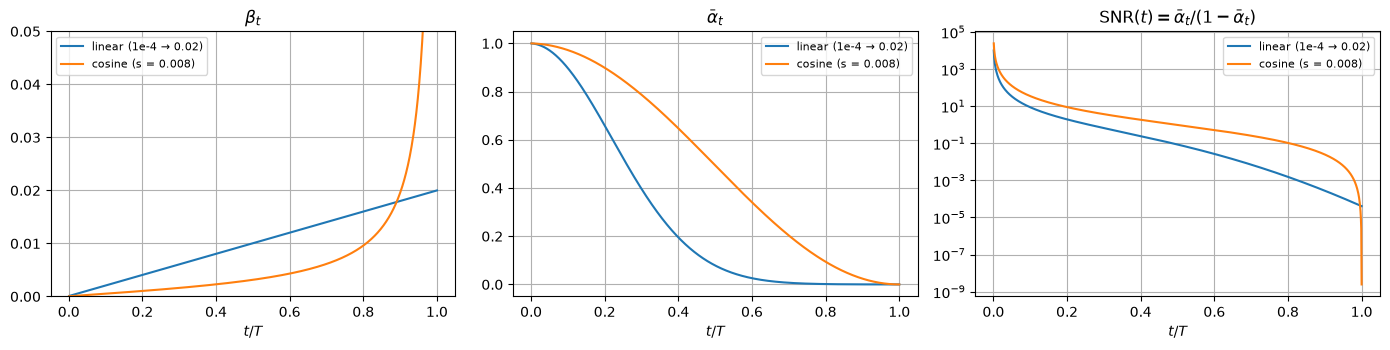

linear (1e-4 → 0.02)  : alpha_bar_T = 4.04e-05, fraction of steps with SNR < 0.01: 0.33
cosine (s = 0.008)    : alpha_bar_T = 2.43e-09, fraction of steps with SNR < 0.01: 0.06


In [5]:
def cosine_betas(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1, dtype=np.float64)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha_bar = f / f[0]
    return np.clip(1.0 - alpha_bar[1:] / alpha_bar[:-1], 0.0, max_beta)

T_big = 1000
schedules = {"linear (1e-4 → 0.02)": make_schedule(linear_betas(T_big)),
             "cosine (s = 0.008)": make_schedule(cosine_betas(T_big))}
tt = np.arange(1, T_big + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name, s in schedules.items():
    ab = s["alpha_bar"].numpy()[1:]
    axes[0].plot(tt / T_big, s["betas"].numpy()[1:], label=name)
    axes[1].plot(tt / T_big, ab, label=name)
    axes[2].semilogy(tt / T_big, ab / (1 - ab), label=name)
axes[0].set_title(r"$\beta_t$"); axes[0].set_ylim(0, 0.05)
axes[1].set_title(r"$\bar\alpha_t$"); axes[2].set_title(r"SNR$(t) = \bar\alpha_t / (1-\bar\alpha_t)$")
for ax in axes:
    ax.set_xlabel("$t / T$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, s in schedules.items():
    print(f"{name:22s}: alpha_bar_T = {s['alpha_bar'][-1].item():.2e},"
          f" fraction of steps with SNR < 0.01: {(s['alpha_bar'][1:] / (1 - s['alpha_bar'][1:]) < 0.01).float().mean().item():.2f}")

Two practical remarks. First, the requirement $\bar\alpha_T\approx0$ matters: if the
final distribution is not close to $\mathcal N(\mathbf 0,I)$, sampling starts from the
wrong distribution. Second, for very small data like our 2-D points, $T=1000$ is overkill;
we use $T=100$ with $\beta_T=0.1$, which gives $\bar\alpha_T\approx 0.006$.

## 3. The reverse process and the training objective

### 3.1 What we want to learn

A generative model runs the chain backwards:

$$p_\theta(\mathbf x_{0:T}) = p(\mathbf x_T)\prod_{t=1}^T p_\theta(\mathbf x_{t-1}\mid\mathbf x_t),\qquad
p(\mathbf x_T) = \mathcal N(\mathbf 0, I),\qquad p_\theta(\mathbf x_{t-1}\mid\mathbf x_t) = \mathcal N\big(\boldsymbol\mu_\theta(\mathbf x_t, t),\ \sigma_t^2 I\big).$$

The true reverse step $q(\mathbf x_{t-1}\mid\mathbf x_t)$ requires knowing the data
distribution, but **conditioned on $\mathbf x_0$** it is tractable. By Bayes,
$q(\mathbf x_{t-1}\mid\mathbf x_t,\mathbf x_0)\propto q(\mathbf x_t\mid\mathbf x_{t-1})\,q(\mathbf x_{t-1}\mid\mathbf x_0)$,
a product of two Gaussians in $\mathbf x_{t-1}$. Collecting the quadratic and linear terms in
the exponent (completing the square) gives

$$q(\mathbf x_{t-1}\mid\mathbf x_t,\mathbf x_0) = \mathcal N\big(\tilde{\boldsymbol\mu}_t(\mathbf x_t,\mathbf x_0),\ \tilde\beta_t I\big),\qquad
\tilde{\boldsymbol\mu}_t = \frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,\mathbf x_0 + \frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,\mathbf x_t,\qquad
\tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t .$$

(The precision is the sum of the two precisions, $\tfrac{\alpha_t}{\beta_t} + \tfrac{1}{1-\bar\alpha_{t-1}} = \tfrac{1-\bar\alpha_t}{\beta_t(1-\bar\alpha_{t-1})}$,
and the mean is the precision-weighted combination.) The posterior mean is a weighted average
of the clean point and the noisy point.

### 3.2 Parameterising by the noise

We do not know $\mathbf x_0$ at sampling time, but the closed form tells us how $\mathbf x_t$
was made: $\mathbf x_0 = \big(\mathbf x_t - \sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon\big)/\sqrt{\bar\alpha_t}$.
Substituting into $\tilde{\boldsymbol\mu}_t$ and simplifying with $\bar\alpha_t = \alpha_t\bar\alpha_{t-1}$
(the coefficient of $\mathbf x_t$ becomes $\frac{\beta_t + \alpha_t - \bar\alpha_t}{\sqrt{\alpha_t}(1-\bar\alpha_t)} = \frac{1}{\sqrt{\alpha_t}}$):

$$\tilde{\boldsymbol\mu}_t = \frac{1}{\sqrt{\alpha_t}}\Big(\mathbf x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\boldsymbol\epsilon\Big).$$

This suggests letting a network $\boldsymbol\epsilon_\theta(\mathbf x_t, t)$ **predict the noise** that was
added, and using the same formula for the model's mean:

$$\boldsymbol\mu_\theta(\mathbf x_t,t) = \frac{1}{\sqrt{\alpha_t}}\Big(\mathbf x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\boldsymbol\epsilon_\theta(\mathbf x_t,t)\Big).$$

### 3.3 The ELBO and the simple loss

A diffusion model is a latent-variable model with latents $\mathbf x_{1:T}$ and a *fixed*
encoder $q(\mathbf x_{1:T}\mid\mathbf x_0)$. Exactly as for the VAE, Jensen's inequality gives
a bound, which after some algebra (Sohl-Dickstein et al., 2015; Ho et al., 2020) decomposes into one term per step:

$$-\log p_\theta(\mathbf x_0) \le \mathbb E_q\Big[\underbrace{\mathrm{KL}\big(q(\mathbf x_T\mid\mathbf x_0)\Vert p(\mathbf x_T)\big)}_{\text{no parameters}}
+ \sum_{t=2}^T \underbrace{\mathrm{KL}\big(q(\mathbf x_{t-1}\mid\mathbf x_t,\mathbf x_0)\,\Vert\, p_\theta(\mathbf x_{t-1}\mid\mathbf x_t)\big)}_{L_{t-1}}
- \log p_\theta(\mathbf x_0\mid\mathbf x_1)\Big].$$

Each $L_{t-1}$ is a KL between two Gaussians with the same fixed variance, so by the
formula from Lecture 9 it is a squared distance between the means, and with the
$\boldsymbol\epsilon$-parameterisation

$$L_{t-1} = \frac{1}{2\sigma_t^2}\big\lVert\tilde{\boldsymbol\mu}_t - \boldsymbol\mu_\theta\big\rVert^2 + \text{const}
= \frac{\beta_t^2}{2\sigma_t^2\,\alpha_t\,(1-\bar\alpha_t)}\,\big\lVert\boldsymbol\epsilon - \boldsymbol\epsilon_\theta(\mathbf x_t, t)\big\rVert^2 + \text{const}.$$

Ho et al. found that simply **dropping the weights** works better in practice, giving the
famous DDPM loss

$$\boxed{\;\mathcal L_{\text{simple}}(\theta) = \mathbb E_{\mathbf x_0\sim\text{data},\ t\sim\mathcal U\{1,\dots,T\},\ \boldsymbol\epsilon\sim\mathcal N(\mathbf 0,I)}
\Big[\big\lVert\boldsymbol\epsilon - \boldsymbol\epsilon_\theta\big(\sqrt{\bar\alpha_t}\,\mathbf x_0 + \sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon,\ t\big)\big\rVert^2\Big].\;}$$

This is a reweighted ELBO: compared with the true bound it puts relatively less weight on
the easy, low-noise steps and more on the harder, high-noise ones, which favours sample quality
over likelihood. Training is a plain regression problem: no adversary, no sampling during
training, no posterior collapse.

### 3.4 The score-function view

Here is a second, illuminating way to read the loss. For the Gaussian $q(\mathbf x_t\mid\mathbf x_0)$,

$$\nabla_{\mathbf x_t}\log q(\mathbf x_t\mid\mathbf x_0) = -\frac{\mathbf x_t - \sqrt{\bar\alpha_t}\,\mathbf x_0}{1-\bar\alpha_t} = -\frac{\boldsymbol\epsilon}{\sqrt{1-\bar\alpha_t}} .$$

So predicting $\boldsymbol\epsilon$ is, up to the factor $-1/\sqrt{1-\bar\alpha_t}$, regressing onto
$\nabla\log q(\mathbf x_t\mid\mathbf x_0)$. **Denoising score matching** (Vincent, 2011) shows that the
minimiser of $\mathbb E\lVert\mathbf s_\theta(\mathbf x_t) - \nabla\log q(\mathbf x_t\mid\mathbf x_0)\rVert^2$ is the score
of the *marginal* noisy distribution, $\nabla_{\mathbf x_t}\log q_t(\mathbf x_t)$, because the regression
target averages over all $\mathbf x_0$ that could have produced $\mathbf x_t$. Hence

$$\mathbf s_\theta(\mathbf x_t, t) := -\frac{\boldsymbol\epsilon_\theta(\mathbf x_t, t)}{\sqrt{1-\bar\alpha_t}} \approx \nabla_{\mathbf x_t}\log q_t(\mathbf x_t).$$

A diffusion model is a **denoising autoencoder at every noise level** (Lecture 9, §3), and
the sampler below can be read as noisy gradient ascent on $\log q_t$ with a decreasing noise level
(annealed Langevin dynamics; Song & Ermon, 2019). Song et al. (2021) unified both views as
discretisations of a stochastic differential equation. Relatedly, **Tweedie's formula** gives the
best guess of the clean data, $\mathbb E[\mathbf x_0\mid\mathbf x_t] = \big(\mathbf x_t - \sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon_\theta\big)/\sqrt{\bar\alpha_t} =: \hat{\mathbf x}_0$,
which we will use for DDIM and for clipping.

### 3.5 Sampling

Training (Algorithm 1 of Ho et al.):

> **repeat:** $\mathbf x_0\sim$ data, $t\sim\mathcal U\{1,\dots,T\}$, $\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,I)$;
> take a gradient step on $\lVert\boldsymbol\epsilon - \boldsymbol\epsilon_\theta(\sqrt{\bar\alpha_t}\mathbf x_0 + \sqrt{1-\bar\alpha_t}\boldsymbol\epsilon, t)\rVert^2$.

Ancestral sampling (Algorithm 2):

> $\mathbf x_T\sim\mathcal N(\mathbf 0, I)$; **for** $t = T,\dots,1$:
> $\ \mathbf z\sim\mathcal N(\mathbf 0,I)$ if $t>1$ else $\mathbf z = \mathbf 0$;
> $\ \mathbf x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(\mathbf x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\boldsymbol\epsilon_\theta(\mathbf x_t,t)\Big) + \sigma_t\mathbf z$.

Two choices of $\sigma_t^2$ are common: $\beta_t$ (optimal if the data were pure noise) and
$\tilde\beta_t$ (optimal for a single deterministic data point); they give similar results. We use
$\sigma_t^2 = \beta_t$. No noise is added in the very last step.

## 4. A diffusion model for 2-D data

### 4.1 The denoiser and its time embedding

$\boldsymbol\epsilon_\theta(\mathbf x_t,t)$ must know *how noisy* its input is, so we feed it the time
step. Feeding the raw integer $t$ works poorly (one input that ranges over two orders of magnitude);
instead we use the **sinusoidal embedding** of the Transformer (Lecture 8):

$$\operatorname{emb}(t) = \big[\sin(\omega_1 t),\dots,\sin(\omega_{D/2} t),\ \cos(\omega_1 t),\dots,\cos(\omega_{D/2} t)\big],\qquad \omega_i = 10000^{-(i-1)/(D/2)} .$$

High frequencies distinguish neighbouring steps, low frequencies encode the coarse position in
the chain. The denoiser is an MLP on the concatenation $[\mathbf x_t,\operatorname{emb}(t)]$.
(Image models use a U-Net and inject the embedding into every block, but the principle is the same.)

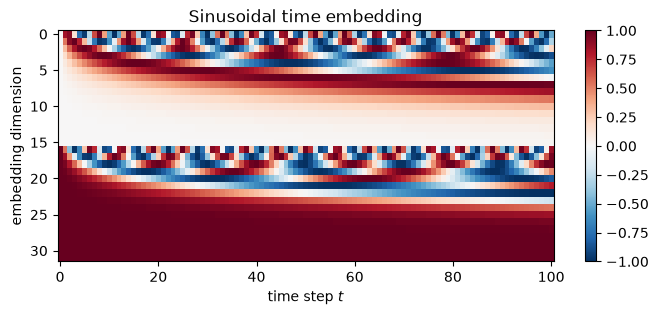

In [6]:
def timestep_embedding(t, dim, max_period=10000.0):
    """Sinusoidal embedding of a (B,) tensor of time steps -> (B, dim) float32 tensor."""
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

emb = timestep_embedding(torch.arange(0, T2 + 1), 32).numpy()
plt.figure(figsize=(8, 3))
plt.imshow(emb.T, aspect="auto", cmap="RdBu_r"); plt.colorbar()
plt.xlabel("time step $t$"); plt.ylabel("embedding dimension"); plt.title("Sinusoidal time embedding"); plt.grid(False)
plt.show()

class Denoiser(nn.Module):
    """epsilon_theta(x_t, t [, y]): an MLP on [x_t, emb(t) (, emb(y))]."""
    def __init__(self, d=2, hidden=128, t_dim=32, n_layers=3, n_classes=None):
        super().__init__()
        self.t_dim = t_dim
        # optional class conditioning (Section 6.2): index n_classes is the "no label" token
        self.y_emb = nn.Embedding(n_classes + 1, t_dim) if n_classes is not None else None
        in_dim = d + t_dim + (t_dim if n_classes is not None else 0)
        layers, width = [], in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(width, hidden), nn.SiLU()]
            width = hidden
        layers.append(nn.Linear(width, d))
        self.net = nn.Sequential(*layers)

    def forward(self, x, t, y=None):
        h = [x, timestep_embedding(t, self.t_dim)]
        if self.y_emb is not None:
            h.append(self.y_emb(y))
        return self.net(torch.cat(h, dim=-1))

### 4.2 Training

The training loop is Algorithm 1 almost verbatim. We draw a fresh mini-batch, a fresh $t$ for
every example and fresh noise, and use Adam with a cosine-decaying learning rate. The optional
`p_uncond` argument is for classifier-free guidance (§6.2) and can be ignored for now.

step     0  loss 1.0981


step   500  loss 0.3782


step  1000  loss 0.3596


step  1500  loss 0.3463


step  2000  loss 0.3421


step  2500  loss 0.3401


step  3000  loss 0.3252


step  3500  loss 0.3294


step  3999  loss 0.3279


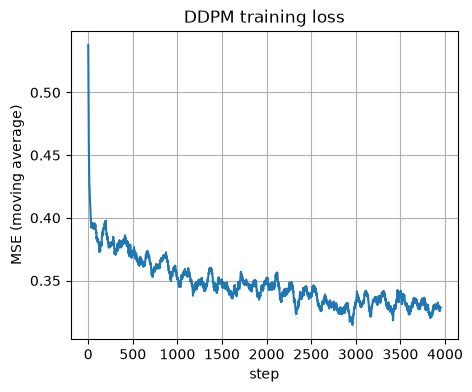

In [7]:
def ddpm_loss(model, x0, sched, y=None):
    B = x0.shape[0]
    t = torch.randint(1, sched["T"] + 1, (B,))
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise, sched)
    return F.mse_loss(model(xt, t, y), noise)

def train_ddpm(model, X, sched, steps=4000, batch_size=256, lr=2e-3, y=None, n_classes=None,
               p_uncond=0.2, seed=0, log_every=500):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lr_sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    losses = []
    for step in range(steps):
        idx = torch.randint(0, X.shape[0], (batch_size,))
        yb = None
        if y is not None:
            yb = y[idx].clone()
            drop = torch.rand(batch_size) < p_uncond
            yb[drop] = n_classes                          # replace label by the "no label" token
        loss = ddpm_loss(model, X[idx], sched, yb)
        opt.zero_grad(); loss.backward(); opt.step(); lr_sched.step()
        losses.append(loss.item())
        if log_every and (step % log_every == 0 or step == steps - 1):
            print(f"step {step:5d}  loss {np.mean(losses[-100:]):.4f}")
    return losses

torch.manual_seed(0)
model2 = Denoiser(d=2, hidden=128, t_dim=32)
losses2 = train_ddpm(model2, X2_t, sched2, steps=4000)
plt.plot(np.convolve(losses2, np.ones(50) / 50, mode="valid"))
plt.xlabel("step"); plt.ylabel("MSE (moving average)"); plt.title("DDPM training loss"); plt.show()

The loss does not go to zero, and it should not. At large $t$ the task is easy, since
$\mathbf x_t\approx\boldsymbol\epsilon$; at very small $t$ it is also fairly easy, since the noisy
point sits right next to the data. The hard steps are the intermediate ones, where several data
points are plausible explanations of $\mathbf x_t$ and the best possible prediction of
$\boldsymbol\epsilon$ is an average over them, with an irreducible error.

### 4.3 Ancestral sampling and the reverse trajectory

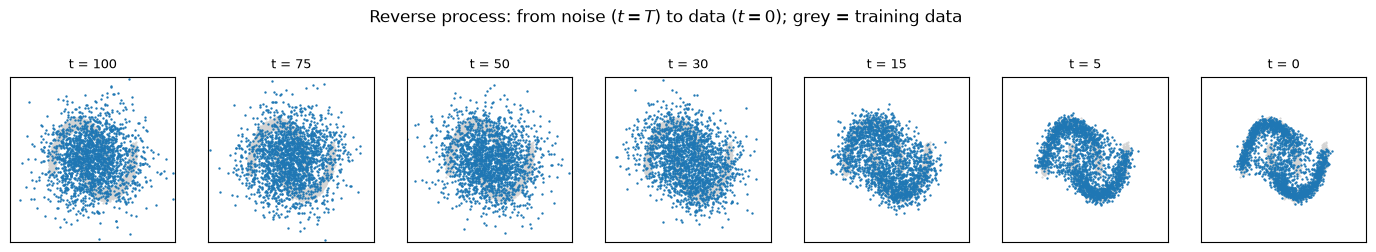

In [8]:
@torch.no_grad()
def p_sample_step(model, x, t, sched, y=None, guidance=0.0, n_classes=None):
    """One step x_t -> x_{t-1} of ancestral sampling (t is a Python int >= 1)."""
    tt = torch.full((x.shape[0],), t, dtype=torch.long)
    eps = model(x, tt, y)
    if guidance != 0.0:                                   # classifier-free guidance, Section 6.2
        y_null = torch.full_like(y, n_classes)
        eps = (1.0 + guidance) * eps - guidance * model(x, tt, y_null)
    beta, alpha, ab = sched["betas"][t], sched["alphas"][t], sched["alpha_bar"][t]
    mean = (x - beta / (1.0 - ab).sqrt() * eps) / alpha.sqrt()
    if t > 1:
        return mean + beta.sqrt() * torch.randn_like(x)
    return mean

@torch.no_grad()
def sample(model, sched, n, d=2, y=None, guidance=0.0, n_classes=None, keep=(), seed=0):
    torch.manual_seed(seed)
    x = torch.randn(n, d)
    snapshots = {sched["T"]: x.clone()}
    for t in range(sched["T"], 0, -1):
        x = p_sample_step(model, x, t, sched, y, guidance, n_classes)
        if (t - 1) in keep:
            snapshots[t - 1] = x.clone()
    return x, snapshots

keep_ts = (75, 50, 30, 15, 5, 0)
x_gen, snaps = sample(model2, sched2, n=2000, keep=keep_ts)

fig, axes = plt.subplots(1, len(snaps), figsize=(2.5 * len(snaps), 2.8))
for ax, t in zip(axes, sorted(snaps, reverse=True)):
    s = snaps[t].numpy()
    ax.scatter(X2[:, 0], X2[:, 1], s=0.3, c="lightgray")
    ax.scatter(s[:, 0], s[:, 1], s=0.5, c="C0")
    ax.set_title(f"t = {t}", fontsize=9)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Reverse process: from noise ($t=T$) to data ($t=0$); grey = training data", y=1.03); plt.show()

Noise condenses onto the two moons. Note that most of the structure appears in the
final third of the reverse process: at large $t$ the score field only pulls points
towards the overall centre of mass, fine detail is resolved at small $t$.

We can follow a few individual points through the chain, and also look at the learned
**score field** $\mathbf s_\theta(\mathbf x,t) = -\boldsymbol\epsilon_\theta(\mathbf x,t)/\sqrt{1-\bar\alpha_t}$ at two noise levels.

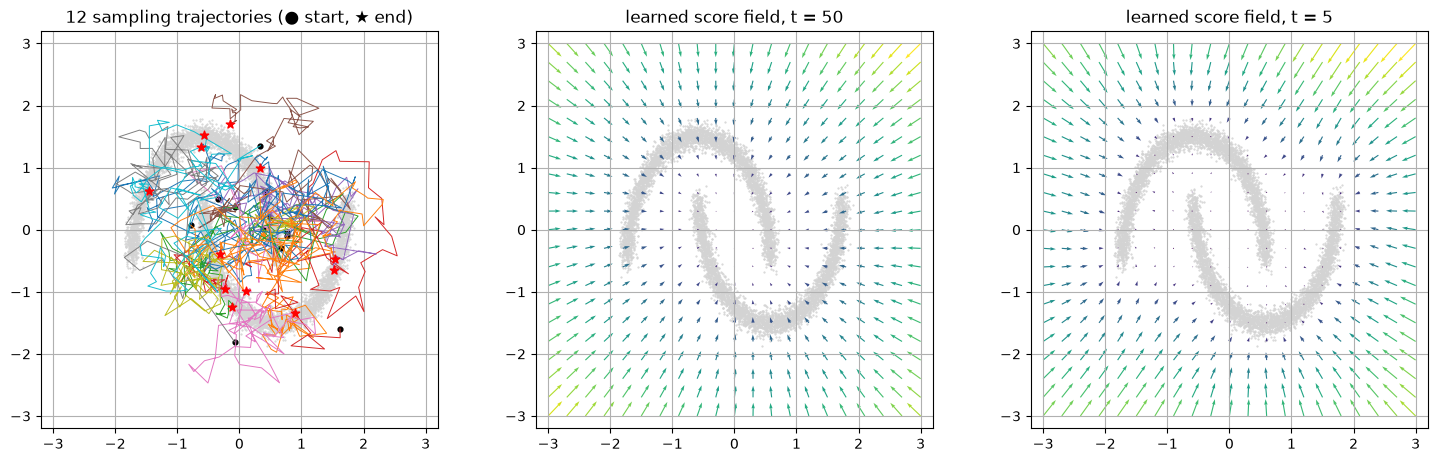

In [9]:
@torch.no_grad()
def trajectories(model, sched, n=12, seed=3):
    torch.manual_seed(seed)
    x = torch.randn(n, 2); path = [x.clone()]
    for t in range(sched["T"], 0, -1):
        x = p_sample_step(model, x, t, sched); path.append(x.clone())
    return torch.stack(path).numpy()                     # (T+1, n, 2)

paths = trajectories(model2, sched2)
gx, gy = np.meshgrid(np.linspace(-3, 3, 21), np.linspace(-3, 3, 21))
grid = torch.from_numpy(np.c_[gx.ravel(), gy.ravel()].astype(np.float32))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].scatter(X2[:, 0], X2[:, 1], s=0.3, c="lightgray")
for i in range(paths.shape[1]):
    axes[0].plot(paths[:, i, 0], paths[:, i, 1], lw=0.7)
    axes[0].scatter(paths[0, i, 0], paths[0, i, 1], marker="o", s=12, c="k")
    axes[0].scatter(paths[-1, i, 0], paths[-1, i, 1], marker="*", s=40, c="r", zorder=3)
axes[0].set_title("12 sampling trajectories (● start, ★ end)")
for ax, t in zip(axes[1:], [50, 5]):
    with torch.no_grad():
        eps = model2(grid, torch.full((len(grid),), t, dtype=torch.long))
    score = (-eps / (1 - sched2["alpha_bar"][t]).sqrt()).numpy()
    ax.scatter(X2[:, 0], X2[:, 1], s=0.3, c="lightgray")
    G_np = grid.numpy()
    ax.quiver(G_np[:, 0], G_np[:, 1], score[:, 0], score[:, 1], np.linalg.norm(score, axis=1), cmap="viridis")
    ax.set_title(f"learned score field, t = {t}")
for ax in axes:
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

At $t=50$ the score is a smooth field pointing roughly towards the data; at $t=5$ it is sharp
and points to the nearest moon. The trajectories are noisy (we add fresh noise at every step),
but they all end on the data manifold.

### 4.4 How good are the samples?

A simple quantitative check for 2-D data: the distance from each generated point to its
nearest training point. The moons have noise level $0.05$ in original units, i.e. their
"thickness" in standardised units is roughly $0.1$. We also compare first and second moments.

fraction of samples within 0.25 of the data: 0.942
sample mean [-0.008 -0.045] | data mean [0. 0.]
sample std  [0.978 1.005] | data std  [1. 1.]
baseline: fraction for samples from N(0, I): 0.653


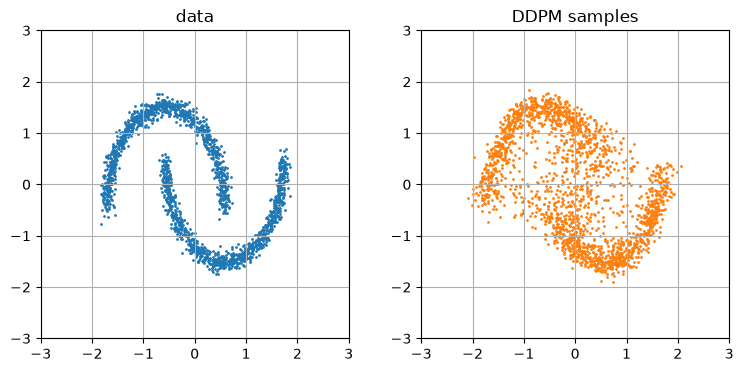

In [10]:
nn_index = NearestNeighbors(n_neighbors=1).fit(X2)

def manifold_fraction(samples, radius=0.25):
    dist, _ = nn_index.kneighbors(np.asarray(samples))
    return float((dist[:, 0] < radius).mean())

xg = x_gen.numpy()
frac = manifold_fraction(xg)
print(f"fraction of samples within 0.25 of the data: {frac:.3f}")
print("sample mean", xg.mean(0).round(3), "| data mean", X2.mean(0).round(3))
print("sample std ", xg.std(0).round(3), "| data std ", X2.std(0).round(3))
print(f"baseline: fraction for samples from N(0, I): {manifold_fraction(rng.standard_normal((2000, 2))):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(X2[:2000, 0], X2[:2000, 1], s=1); axes[0].set_title("data")
axes[1].scatter(xg[:, 0], xg[:, 1], s=1, c="C1"); axes[1].set_title("DDPM samples")
for ax in axes:
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.show()

In [11]:
assert frac > 0.75, frac
assert np.all(np.abs(xg.mean(0)) < 0.2) and np.all(np.abs(xg.std(0) - 1.0) < 0.2)

## 5. A small DDPM on the digits

Nothing in the method is specific to 2-D: we only change the data dimension. We scale the
$8\times8$ digits to $[-1, 1]$ (so the data have roughly the scale of the noise), use $T=200$
with a linear schedule from $10^{-4}$ to $0.05$, and a wider MLP denoiser. Real image models use
convolutional U-Nets and train for days; ours trains in seconds, so expect samples that are only
vaguely digit-like.

**Clipping trick.** For bounded data a common improvement is to compute Tweedie's estimate
$\hat{\mathbf x}_0$ at every step, clip it to $[-1,1]$, and then take the posterior mean
$\tilde{\boldsymbol\mu}_t(\mathbf x_t,\hat{\mathbf x}_0)$ from §3.1 with variance $\tilde\beta_t$.
Without clipping this is algebraically the same as the $\boldsymbol\epsilon$-form step we used
above (you can verify this from §3.2); with clipping it prevents the sampler from drifting
outside the range of the data.

digits schedule: alpha_bar_T = 0.0061
step     0  loss 1.0104


step  1000  loss 0.2210


step  2000  loss 0.2002


step  2999  loss 0.1925


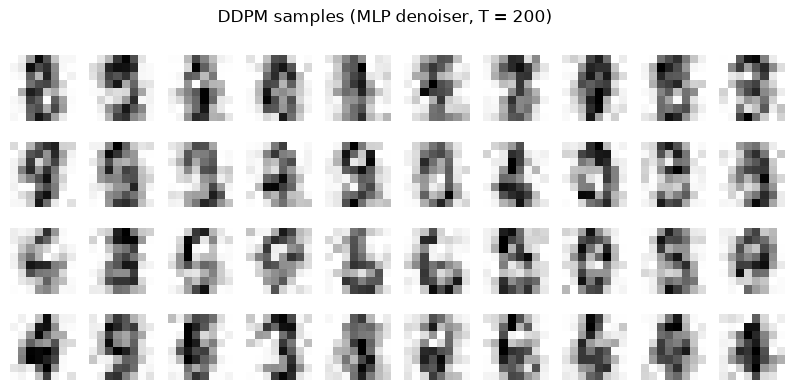

In [12]:
digits = load_digits()
Xd = (digits.data / 16.0 * 2.0 - 1.0).astype(np.float32)   # in [-1, 1]
Xd_t = torch.from_numpy(Xd)

Td = 200
sched_d = make_schedule(linear_betas(Td, 1e-4, 0.05))
print(f"digits schedule: alpha_bar_T = {sched_d['alpha_bar'][-1].item():.4f}")

torch.manual_seed(0)
model_d = Denoiser(d=64, hidden=256, t_dim=32, n_layers=3)
losses_d = train_ddpm(model_d, Xd_t, sched_d, steps=3000, batch_size=128, lr=1e-3, log_every=1000)

@torch.no_grad()
def sample_clipped(model, sched, n, d, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(n, d)
    for t in range(sched["T"], 0, -1):
        tt = torch.full((n,), t, dtype=torch.long)
        ab, ab_prev = sched["alpha_bar"][t], sched["alpha_bar_prev"][t]
        beta, alpha = sched["betas"][t], sched["alphas"][t]
        eps = model(x, tt)
        x0_hat = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1.0, 1.0)
        mean = (ab_prev.sqrt() * beta / (1 - ab)) * x0_hat + (alpha.sqrt() * (1 - ab_prev) / (1 - ab)) * x
        x = mean + sched["post_var"][t].sqrt() * torch.randn_like(x) if t > 1 else mean
    return x

xd_gen = sample_clipped(model_d, sched_d, n=40, d=64).numpy()

def show_digits(imgs, n_cols=10, title=None):
    n_rows = int(math.ceil(len(imgs) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols, n_rows + 0.3), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im in zip(axes.ravel(), imgs):
        ax.imshow(im.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
    if title:
        plt.suptitle(title)
    plt.show()

show_digits(xd_gen, title="DDPM samples (MLP denoiser, T = 200)")

Many samples are recognisable digits; others are plausible strokes that do not quite commit to
a class. Are they just copies of training images? Show each sample next to its nearest
training image:

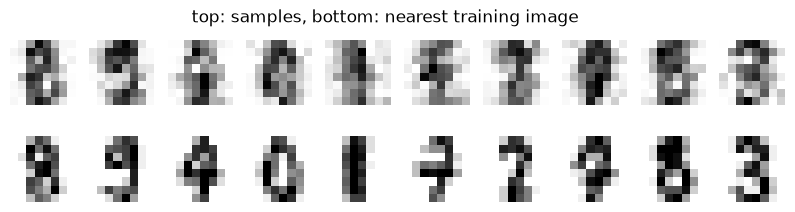

mean distance sample -> nearest training image: 3.19
mean distance between a training image and its nearest other training image: 2.12


In [13]:
nn_d = NearestNeighbors(n_neighbors=1).fit(Xd)
dist_d, idx_d = nn_d.kneighbors(xd_gen[:10])
show_digits(np.concatenate([xd_gen[:10], Xd[idx_d[:, 0]]]), title="top: samples, bottom: nearest training image")
print("mean distance sample -> nearest training image:", dist_d.mean().round(2))
print("mean distance between a training image and its nearest other training image:",
      NearestNeighbors(n_neighbors=2).fit(Xd).kneighbors(Xd[:200])[0][:, 1].mean().round(2))

The samples resemble but do not duplicate training images. (Memorisation is a real concern for
large diffusion models trained on small datasets; Carlini et al., 2023, extracted training images
from Stable Diffusion.)

Finally, the reverse process on digits, from noise to image:

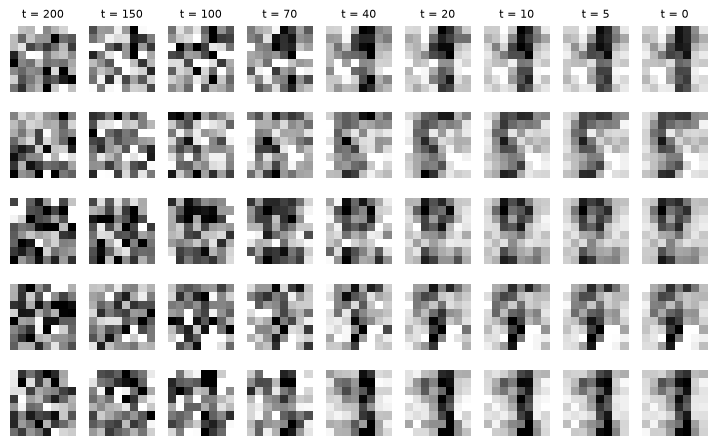

In [14]:
@torch.no_grad()
def reverse_snapshots(model, sched, n, d, ts, seed=1):
    torch.manual_seed(seed)
    x = torch.randn(n, d); out = []
    for t in range(sched["T"], 0, -1):
        if t in ts:
            out.append(x.clone())
        x = p_sample_step(model, x, t, sched)
    out.append(x.clone())
    return out

ts_show = (200, 150, 100, 70, 40, 20, 10, 5)
snaps_d = reverse_snapshots(model_d, sched_d, n=5, d=64, ts=ts_show)
fig, axes = plt.subplots(5, len(snaps_d), figsize=(len(snaps_d), 5.4))
for j, s in enumerate(snaps_d):
    for i in range(5):
        axes[i, j].imshow(s[i].clamp(-1.5, 1.5).reshape(8, 8).numpy(), cmap="gray_r", vmin=-1.5, vmax=1.5)
        axes[i, j].axis("off")
    axes[0, j].set_title(f"t = {ts_show[j]}" if j < len(ts_show) else "t = 0", fontsize=8)
plt.show()

## 6. Beyond DDPM: faster sampling and guidance

### 6.1 DDIM: deterministic, fewer steps

Ancestral sampling needs one network evaluation per step, i.e. $T$ evaluations, which made
early diffusion models very slow. Song, Meng & Ermon (2021) noticed that the training loss only
depends on the marginals $q(\mathbf x_t\mid\mathbf x_0)$, not on the Markov chain that produced them.
There is a family of non-Markovian forward processes with the same marginals, and hence the same
trained $\boldsymbol\epsilon_\theta$ can be used with a different sampler. The **DDIM** update from
$t$ to an earlier time $s<t$ (with zero added noise, $\eta = 0$) is

$$\hat{\mathbf x}_0 = \frac{\mathbf x_t - \sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon_\theta(\mathbf x_t,t)}{\sqrt{\bar\alpha_t}},\qquad
\mathbf x_s = \sqrt{\bar\alpha_s}\,\hat{\mathbf x}_0 + \sqrt{1-\bar\alpha_s}\,\boldsymbol\epsilon_\theta(\mathbf x_t, t).$$

Read it as: estimate the clean point, then re-noise it to level $s$ *using the predicted noise
instead of fresh noise*. The map from $\mathbf x_T$ to $\mathbf x_0$ becomes deterministic (an ODE
solver, in the continuous-time view), and because it is smooth we can skip steps: $s$ need not be
$t-1$. Let us sample the moons model with 10 and 20 steps instead of 100.

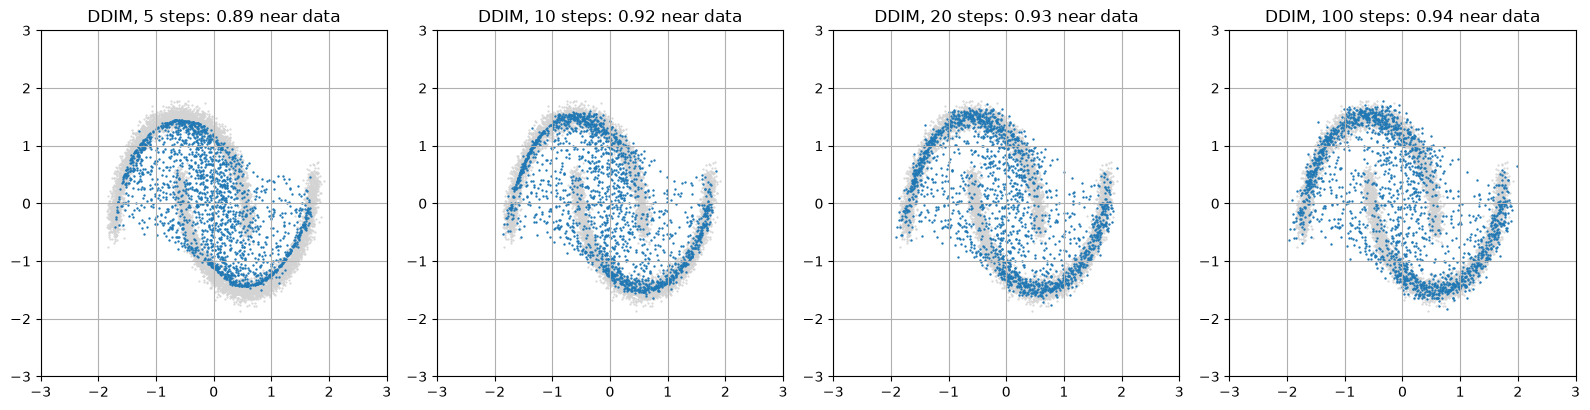

(ancestral DDPM sampling with 100 steps: 0.94 near data)


In [15]:
@torch.no_grad()
def ddim_sample(model, sched, n, n_steps, d=2, seed=0):
    torch.manual_seed(seed)
    ts = np.linspace(sched["T"], 0, n_steps + 1).round().astype(int)   # e.g. 100, 90, ..., 0
    x = torch.randn(n, d)
    for t, s in zip(ts[:-1], ts[1:]):
        tt = torch.full((n,), int(t), dtype=torch.long)
        eps = model(x, tt)
        ab_t, ab_s = sched["alpha_bar"][int(t)], sched["alpha_bar"][int(s)]
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x = ab_s.sqrt() * x0_hat + (1 - ab_s).sqrt() * eps
    return x

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, n_steps in zip(axes, [5, 10, 20, 100]):
    xs = ddim_sample(model2, sched2, 2000, n_steps).numpy()
    ax.scatter(X2[:, 0], X2[:, 1], s=0.3, c="lightgray"); ax.scatter(xs[:, 0], xs[:, 1], s=0.5)
    ax.set_title(f"DDIM, {n_steps} steps: {manifold_fraction(xs):.2f} near data")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()
print(f"(ancestral DDPM sampling with 100 steps: {frac:.2f} near data)")

With 10–20 deterministic steps DDIM is already close to 100-step ancestral sampling, a 5–10×
speed-up for free. Modern samplers (DPM-Solver, Heun/EDM, distillation into one-to-four-step
models, consistency models) push this further.

### 6.2 Conditioning and classifier-free guidance

To generate *a specific class* $y$ (or an image matching a text prompt), give the denoiser the
condition as an extra input: $\boldsymbol\epsilon_\theta(\mathbf x_t,t,y)$. In score language it now
estimates $\nabla\log q_t(\mathbf x_t\mid y)$. By Bayes,

$$\nabla\log q_t(\mathbf x_t\mid y) = \nabla\log q_t(\mathbf x_t) + \nabla\log q_t(y\mid\mathbf x_t),$$

so conditioning adds a "classifier gradient" pushing samples towards regions where $y$ is likely.
**Guidance** amplifies this term by a factor $1+w$. Classifier guidance (Dhariwal & Nichol, 2021)
needs a separately trained noisy classifier; **classifier-free guidance** (Ho & Salimans, 2022)
gets both terms from a single network trained with the label randomly *dropped* (replaced by a
"null" token $\varnothing$) some fraction of the time:

$$\tilde{\boldsymbol\epsilon} = (1+w)\,\boldsymbol\epsilon_\theta(\mathbf x_t,t,y) - w\,\boldsymbol\epsilon_\theta(\mathbf x_t,t,\varnothing).$$

$w=0$ is ordinary conditional sampling; $w>0$ trades diversity for fidelity to the condition. This
is the knob called "guidance scale" in text-to-image systems. A tiny demo on the two moons, with the
moon index as the class:

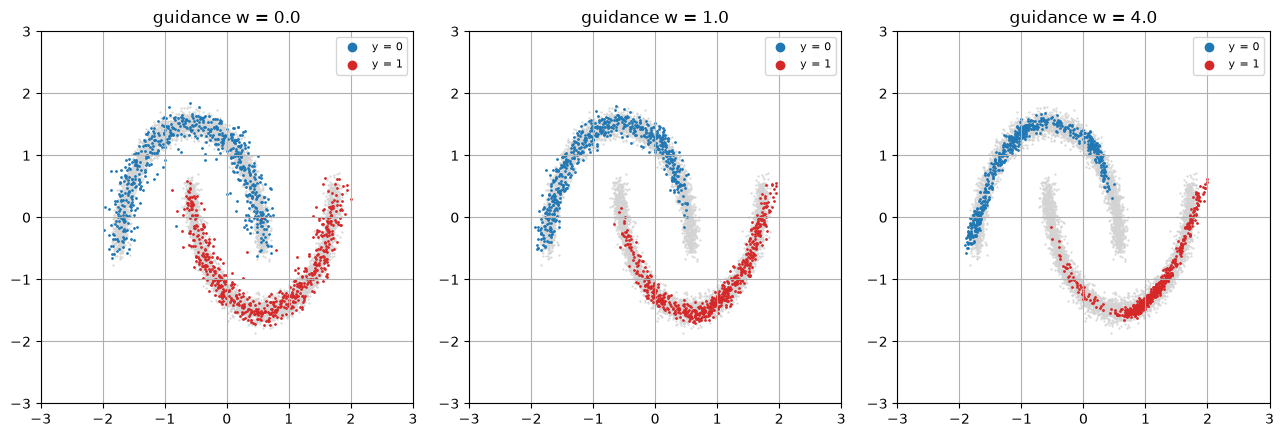

In [16]:
torch.manual_seed(0)
model_c = Denoiser(d=2, hidden=128, t_dim=32, n_classes=2)
_ = train_ddpm(model_c, X2_t, sched2, steps=3000, y=y2_t, n_classes=2, p_uncond=0.2, log_every=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, w in zip(axes, [0.0, 1.0, 4.0]):
    ax.scatter(X2[:, 0], X2[:, 1], s=0.3, c="lightgray")
    for c, col in [(0, "C0"), (1, "C3")]:
        yc = torch.full((600,), c, dtype=torch.long)
        xs, _ = sample(model_c, sched2, 600, y=yc, guidance=w, n_classes=2, seed=c)
        xs = xs.numpy()
        ax.scatter(xs[:, 0], xs[:, 1], s=1, c=col, label=f"y = {c}")
    ax.set_title(f"guidance w = {w}"); ax.legend(markerscale=6, fontsize=8)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

With $w = 0$ each class covers its moon (with a few stray points near the other one). As $w$ grows,
the samples are pushed away from the region where the classes could be confused and concentrate on
the most "class-typical" parts of each moon: higher fidelity, lower diversity. Too much guidance
overshoots and produces artefacts, just as in large text-to-image models.

### 6.3 Other ingredients of modern systems (for orientation)

* **Latent diffusion** (Rombach et al., 2022; "Stable Diffusion"): run the diffusion model in the
  latent space of a pretrained autoencoder (Lecture 9!) instead of in pixel space. Much cheaper.
* **Architectures:** U-Nets with residual blocks and self-attention (Lectures 6–8); more recently
  pure Transformers on image patches (Diffusion Transformers, DiT).
* **Text conditioning:** the condition $y$ is a sequence of text-encoder embeddings injected via
  cross-attention (Lecture 8).
* **Flow matching / rectified flows** (Lipman et al., 2023; Liu et al., 2023): regress a velocity field
  that transports noise to data along (nearly) straight paths; closely related to DDIM and now
  widely used.

## Summary

* **Forward process:** $q(\mathbf x_t\mid\mathbf x_{t-1}) = \mathcal N(\sqrt{1-\beta_t}\mathbf x_{t-1},\beta_t I)$ with
  closed form $\mathbf x_t = \sqrt{\bar\alpha_t}\mathbf x_0 + \sqrt{1-\bar\alpha_t}\boldsymbol\epsilon$, $\bar\alpha_t = \prod_{s\le t}(1-\beta_s)$.
* **Schedules** control the SNR $\bar\alpha_t/(1-\bar\alpha_t)$; cosine spends more steps at useful
  intermediate noise levels than linear.
* **Training:** sample $t$ and $\boldsymbol\epsilon$, regress $\boldsymbol\epsilon_\theta(\mathbf x_t, t)$ onto $\boldsymbol\epsilon$. This is a reweighted
  ELBO, and equivalently **denoising score matching**: $-\boldsymbol\epsilon_\theta/\sqrt{1-\bar\alpha_t}\approx\nabla\log q_t$.
* **Sampling:** start from $\mathcal N(\mathbf 0,I)$ and apply
  $\mathbf x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(\mathbf x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\boldsymbol\epsilon_\theta\big) + \sigma_t\mathbf z$
  $T$ times; **DDIM** gives a deterministic sampler that can skip most steps.
* **Classifier-free guidance** combines conditional and unconditional predictions to trade
  diversity for fidelity.

## Looking back at the course

Diffusion models are a good place to finish because they use almost everything we have covered:

| Lecture | Where it shows up in a diffusion model |
|---|---|
| 1 Linear models | the loss-minimisation framing; the MSE regression onto $\boldsymbol\epsilon$ is "prediction minus target" again |
| 2 MLPs & backprop | our denoiser is an MLP; every gradient step is backpropagation |
| 3 Optimisation & initialisation | Adam, learning-rate schedules, (in practice) EMA of the weights |
| 4 PyTorch | the whole implementation: tensors, broadcasting, autograd, `nn.Module` |
| 5 Regularisation | the noise itself acts as data augmentation; label dropout in CFG is dropout on the condition |
| 6 CNNs | image denoisers are convolutional U-Nets |
| 7 RNNs | sampling is an iterative, sequential process with a shared network applied at every step |
| 8 Attention & Transformers | sinusoidal time embeddings; self- and cross-attention in U-Nets and DiTs |
| 9 Autoencoders & VAEs | the ELBO, Gaussian KLs, the reparameterisation $\mathbf x_t = \sqrt{\bar\alpha_t}\mathbf x_0 + \sqrt{1-\bar\alpha_t}\boldsymbol\epsilon$, denoising autoencoders and the score, latent diffusion |

The common thread: choose a model family, write down a differentiable objective, and let
stochastic gradient descent and automatic differentiation do the rest. The specific
architectures will keep changing; the principles in this course will not.

**Further reading.**
Sohl-Dickstein et al., "Deep unsupervised learning using nonequilibrium thermodynamics", ICML 2015;
Ho, Jain & Abbeel, "Denoising diffusion probabilistic models", NeurIPS 2020;
Song et al., "Score-based generative modeling through stochastic differential equations", ICLR 2021;
Nichol & Dhariwal, "Improved denoising diffusion probabilistic models", ICML 2021;
Song, Meng & Ermon, "Denoising diffusion implicit models", ICLR 2021;
Ho & Salimans, "Classifier-free diffusion guidance", 2022;
Karras et al., "Elucidating the design space of diffusion-based generative models", NeurIPS 2022;
Bishop & Bishop, *Deep Learning: Foundations and Concepts* (2024), ch. 20;
Calvin Luo, "Understanding diffusion models: a unified perspective" (2022), an accessible derivation of everything above.